# Visualize crops, positive pairs, and augmentations

Used to tune `crop_size` and per-augmentation strengths before any training. Each cell is independent — re-run individual cells after editing `cfg`.


In [ ]:
# Cell 1 — pick a zarr, build the dataset, print key facts, define z-grid helpers.
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np

from config import Config
from data.picker import pick_zarr_path
from data.dataset import ZarrCellDataset

cfg = Config()
if cfg.zarr_path is None:
    cfg.zarr_path = pick_zarr_path()

ds = ZarrCellDataset(cfg)

print('zarr_path           :', cfg.zarr_path)
print('arr.shape (T,C,Z,Y,X):', tuple(ds.arr.shape))
print('arr.dtype           :', ds.arr.dtype)
print('arr.chunks          :', ds.arr.chunks)
print('z_thickness             :', cfg.z_thickness)
print('Δt frames               :', (ds.delta_t_min, ds.delta_t_max))
print('z range slices          :', (ds.z_min, ds.z_max))


def z_grid(img, ncols=5):
    """tile a (z, h, w) volume into one 2d image with ncols slices per row."""
    Z, H, W = img.shape
    nrows = (Z + ncols - 1) // ncols
    out = np.zeros((nrows * H, ncols * W), dtype=img.dtype)
    for i in range(Z):
        r, c = divmod(i, ncols)
        out[r*H:(r+1)*H, c*W:(c+1)*W] = img[i]
    return out


def z_strip(img):
    """tile (z, h, w) into a single horizontal strip (h, z*w)."""
    return np.concatenate(list(img), axis=1)


meta: {'t1': 98, 't2': 94, 'z': 216, 'z_end': 226, 'x': 261, 'y': 132}
view shape (Z, H, W): (10, 128, 128)


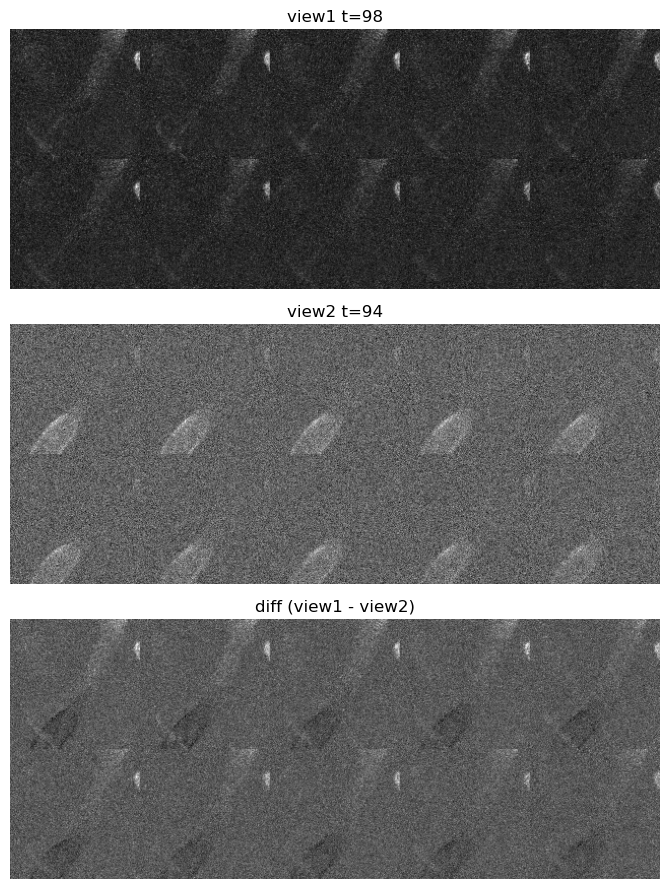

In [2]:
# Cell 2 — pull one positive pair, show view1 / view2 / diff as z-grids.
import matplotlib.pyplot as plt

pair = next(iter(ds))
v1 = pair['view1'][0].numpy()   # (Z, H, W)
v2 = pair['view2'][0].numpy()
meta = pair['meta']
print('meta:', meta)
print('view shape (Z, H, W):', v1.shape)

fig, axes = plt.subplots(3, 1, figsize=(14, 9))
for ax, vol, title in zip(
    axes,
    (v1, v2, v1 - v2),
    (f"view1 t={int(meta['t1'])}", f"view2 t={int(meta['t2'])}", 'diff (view1 - view2)'),
):
    ax.imshow(z_grid(vol), cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout(); plt.show()


In [ ]:
# Cell 3 — N independently augmented variants of the SAME raw crop, each as a z-strip row.
import numpy as np
import torch
import matplotlib.pyplot as plt
from data.augmentations import build_augmentations

# reload the same base crop directly, before augs, using the meta from cell 2.
m = meta
crop_h = crop_w = cfg.crop_size
base = ds._load_crop(int(m['t1']), int(m['z']), int(m['y']), int(m['x']), crop_h, crop_w)

augment = build_augmentations(cfg)

n_variants = 8
fig, axes = plt.subplots(n_variants, 1, figsize=(14, 1.6 * n_variants))
for ax in axes:
    out = augment(base.clone())[0].numpy()  # (z, h, w)
    ax.imshow(z_strip(out), cmap='gray')
    ax.axis('off')
plt.suptitle(f'{n_variants} independent augmentations of the same crop, each row is the {cfg.z_thickness} z-slices')
plt.tight_layout(); plt.show()


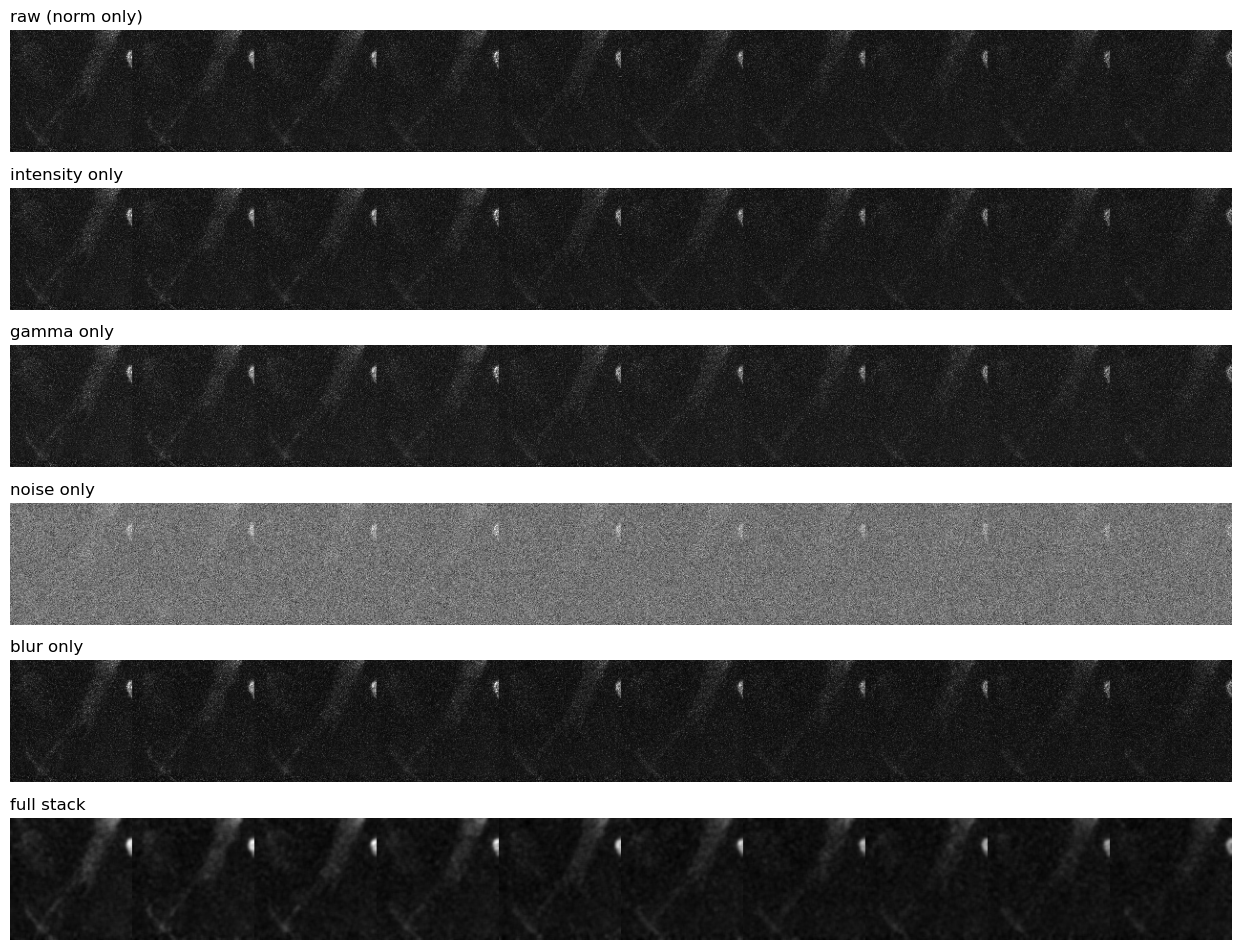

In [4]:
# Cell 4 — per-augmentation isolation. Each row is one augmentation mode shown as a z-strip.
import copy
import matplotlib.pyplot as plt

def isolate(name):
    c = copy.deepcopy(cfg)
    for attr in ('aug_intensity', 'aug_gamma', 'aug_noise', 'aug_blur'):
        getattr(c, attr).enabled = (attr == name)
    # Always keep per-crop norm so visual ranges are comparable.
    c.aug_percrop_norm.enabled = True
    # Force application this run (p=1.0) for a clear demo.
    if name in ('aug_intensity','aug_gamma','aug_noise','aug_blur'):
        getattr(c, name).p = 1.0
    return build_augmentations(c)

configs = [
    ('raw (norm only)', None),
    ('intensity only', 'aug_intensity'),
    ('gamma only', 'aug_gamma'),
    ('noise only', 'aug_noise'),
    ('blur only', 'aug_blur'),
    ('full stack', 'all'),
]
fig, axes = plt.subplots(len(configs), 1, figsize=(14, 1.6 * len(configs)))
for ax, (title, key) in zip(axes, configs):
    if key is None:
        c = copy.deepcopy(cfg)
        for a in ('aug_intensity','aug_gamma','aug_noise','aug_blur'):
            getattr(c, a).enabled = False
        aug = build_augmentations(c)
    elif key == 'all':
        aug = build_augmentations(cfg)
    else:
        aug = isolate(key)
    out = aug(base.clone())[0].numpy()  # (Z, H, W)
    ax.imshow(z_strip(out), cmap='gray')
    ax.set_title(title, loc='left')
    ax.axis('off')
plt.tight_layout(); plt.show()


In [ ]:
# Cell 5 — crop-size sweep on one anchor; overlay rectangles on a MIP of the crop's z range.
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import torch.nn.functional as F
import torch

# mip across the crop's z range so the rectangles match the volume the model actually sees.
z0 = int(meta['z'])
z1 = z0 + cfg.z_thickness
frame = ds.arr[int(meta['t1']), cfg.channel, z0:z1, :, :].compute()
frame = np.asarray(frame, dtype=np.float32).max(axis=0)  # (y, x) mip across z
frame = np.clip(frame, 0, cfg.max_intensity) / cfg.max_intensity

# display-only downsample to keep the overview frame small; the model still sees native pixels.
display_ds = 4
disp = torch.from_numpy(frame).unsqueeze(0).unsqueeze(0)
disp = F.interpolate(disp, scale_factor=1/display_ds, mode='bilinear', align_corners=False)
disp = disp.squeeze().numpy()

x_off = int(meta['x']); y_off = int(meta['y'])
sizes = [64, 96, 128, 160, 224]
colors = ['tab:red','tab:orange','tab:green','tab:blue','tab:purple']

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(disp, cmap='gray')
for s, c in zip(sizes, colors):
    rect = patches.Rectangle(
        (x_off / display_ds, y_off / display_ds),
        s / display_ds, s / display_ds,
        linewidth=2, edgecolor=c, facecolor='none', label=f'crop_size={s}',
    )
    ax.add_patch(rect)
ax.legend(loc='upper right')
ax.set_title(f'crop-size sweep at t={int(meta["t1"])}, MIP over z=[{z0},{z1})')
ax.axis('off')
plt.tight_layout(); plt.show()
